## Week 9: Gradient Boosting

In [3]:
# Using insurance.csv (the predicting medical insurance premiums) for this week

!pip install pandas numpy matplotlib scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('insurance.csv')

# Turn text columns (sex, smoker, region) into binary columns
X = pd.get_dummies(df.drop(columns='charges'), drop_first=True)
y = df['charges']

# 80/20 training/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

test_pred = gb.predict(X_test)
print('Train R2:', round(r2_score(y_train, gb.predict(X_train)), 3))
print('Test R2: ', round(r2_score(y_test, test_pred), 3))
print('Test RMSE: $', round(np.sqrt(mean_squared_error(y_test, test_pred)), 0))

Train R2: 0.9
Test R2:  0.879
Test RMSE: $ 4331.0


The gradient boosting model explains 90% of the variation in charges on the data it learned from. That is very high! 

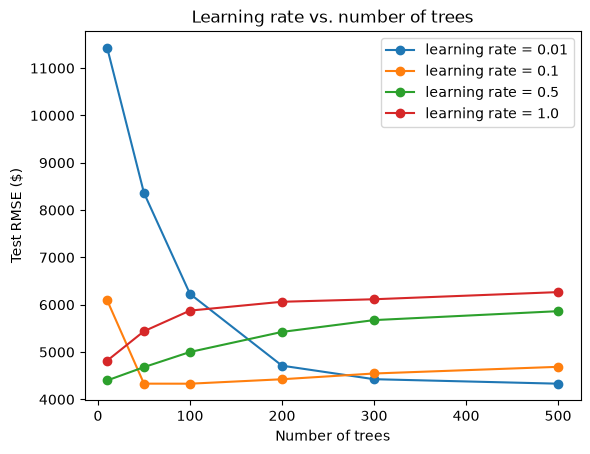

In [6]:
learning_rates = [0.01, 0.1, 0.5, 1.0]
tree_counts = [10, 50, 100, 200, 300, 500]

for lr in learning_rates:
    rmse_list = []
    for n in tree_counts:
        model = GradientBoostingRegressor(learning_rate=lr, n_estimators=n, random_state=42)
        model.fit(X_train, y_train)
        rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
        rmse_list.append(rmse)
    plt.plot(tree_counts, rmse_list, marker='o', label=f'learning rate = {lr}')

plt.xlabel('Number of trees')
plt.ylabel('Test RMSE ($)')
plt.title('Learning rate vs. number of trees')
plt.legend()
plt.show()

With a low learning rate (0.01), the model needed a lot of trees before the error came down. With high learning rates (0.5 and 1.0), the error actually got worse as I added more trees, climbing to around $5,900–$6,300, which tells me those models were overfitting. A learning rate of 0.1 worked best!

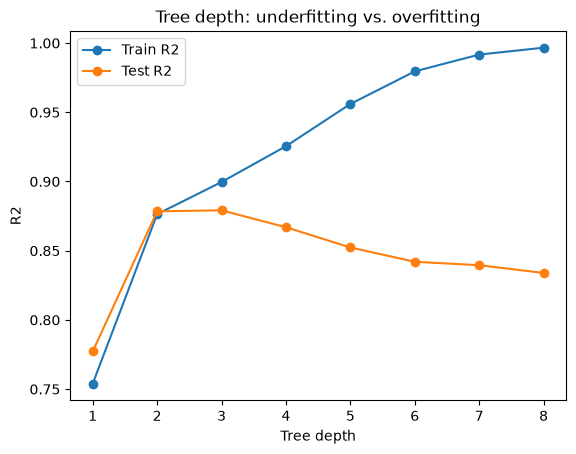

In [8]:
depths = range(1, 9)
train_scores = []
test_scores = []

for d in depths:
    model = GradientBoostingRegressor(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(r2_score(y_train, model.predict(X_train)))
    test_scores.append(r2_score(y_test, model.predict(X_test)))

plt.plot(depths, train_scores, marker='o', label='Train R2')
plt.plot(depths, test_scores, marker='o', label='Test R2')
plt.xlabel('Tree depth')
plt.ylabel('R2')
plt.title('Tree depth: underfitting vs. overfitting')
plt.legend()
plt.show()

When I changed the tree depth, Depth 1 was too simple and significantly underfit the data, with a train R² of only about 0.78. Depths 2 and 3 worked best, with a train and test R² of about 0.88. Past depth 3, the training score kept climbing toward 1.0 while the test score dropped to about 0.83, which shows the deeper trees were overfitting the training data.

In [10]:
# Overfit model vs. the same model with regularization
plain = GradientBoostingRegressor(max_depth=5, n_estimators=300, random_state=42)
regular = GradientBoostingRegressor(max_depth=5, n_estimators=300, min_samples_leaf=20,
                                    subsample=0.8, random_state=42)

for name, model in [('No regularization', plain), ('With regularization', regular)]:
    model.fit(X_train, y_train)
    print(name, '| Train R2:', round(r2_score(y_train, model.predict(X_train)), 3),
          '| Test R2:', round(r2_score(y_test, model.predict(X_test)), 3))

No regularization | Train R2: 0.992 | Test R2: 0.822
With regularization | Train R2: 0.945 | Test R2: 0.858


To test regularization, I started with a model that I knew would overfit. In this case it was a depth of 5 and 300 trees. Without regularization, it scored 0.992 R2 on the training data but only 0.822 on the test data. When I added regularization by requiring at least 20 records in each leaf and training each tree on a random 80% of the data, the training R2 dropped to 0.945, but the test score improved to 0.858. This shows that regularlization improved the test R2 and helped prevent overfitting.